# 第 36 章：能源、商品与环境衍生品

本章各个算例、各张表与各幅图中的每一个数字，按顺序重算一遍。**用 NumPy、SciPy 与 Matplotlib**；
持有成本关系、布莱克公式、Margrabe 交换期权、尖峰模型的混合分布与巴舍利耶度日公式都是逐条写出来的，
而不是从库里调用，于是正文里的公式与代码完全一致。

| 节 | 复现的内容 | 例／图 |
|---|---|---|
| 1 | 从曲线读出库存：隐含便利收益 | 36.1 |
| 2 | Samuelson 期限效应 | 36.2 |
| 3 | 图 36.1 的两幅子图 | 图 36.1 |
| 4 | 尖峰模型对照匹配的对数正态：矩与分位数 | 36.3 |
| 5 | 每日上限期权：算出的 $c(100)$ 与各执行价的表 | 36.3 |
| 6 | 每日上限期权序列对照以月平均价为标的的上限期权（模拟） | 36.4 |
| 7 | 发电厂是一份交换期权，以及 3-2-1 裂解价差 | 36.5 |
| 8 | 仓储：内在价值 | 36.6 |
| 9 | 单因子与双因子下的日历价差期权 | 36.7 |
| 10 | 品级、地点与时点基差 | 36.8 |
| 11 | 堆叠与展期：展期成本与保证金时点 | 36.9 |
| 12 | 碳配额远期与隐含便利收益 | 36.10 |
| 13 | 减排成本曲线上的出清价格 | 36.11 |
| 14 | 双峰密度上的期权：价格、隐含波动率、delta 误差 | 36.12 |
| 15 | 两个密度与驼峰 | 图 36.2 |
| 16 | 度日期权、去趋势与站点与负荷对冲 | 36.13 |
| 17 | 巨灾债券的倍数 | 第 36.16 节 |

本章有一处没有对应的单元：表 36.1 列出各种电力合约及其定价方法，其中没有数字。

每个单元都把算出来的值印在本章所印的值旁边。闭式解得到的数字标为 **ok** 或 **DIFFERS**。
例 36.4 是模拟，因此相应单元印出的是*模拟估计*，与本书的数值并列，在有定义时给出以标准误差计的差距，
但从不标记。整本笔记本不到一分钟即可跑完。

表头保留英文：中文字符在等宽终端里是双宽的，而 Python 的 `%-50s` 按字符数计。

下面这几个辅助函数全篇通用。`black(F, K, v)` 是布莱克的未贴现看涨期权价，用*总*波动率
$v = \sigma\sqrt{T}$ 写出，这正是本章在式 (36.4) 中的写法；它同时返回 $N(d_1)$，因为例 36.12 需要 delta。
`bisect` 是本章为尖峰模型的分位数所描述的求根方法，这里也用它来反解隐含波动率。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import log, sqrt, exp, pi
from scipy.stats import norm

N, phi = norm.cdf, norm.pdf
BAD = []

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one, told apart by dash pattern as well as color.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-4):
    """A deterministic figure, printed beside the chapter's. `tol` is absolute."""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-50s %12.4f   book %11.4f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))


def sim(label, got, printed, se=None):
    """A simulated figure: printed beside the chapter's, never flagged, gap in s.e. if known."""
    gap = "" if se is None else "(%+.1f s.e.)" % ((got - printed) / se)
    print("%-50s %12.4f   book %11.4f   %s" % (label, got, printed, gap))


def black(F, K, v):
    """Black's undiscounted call with total volatility v = sigma sqrt(T); returns (call, N(d1))."""
    d1 = (log(F / K) + 0.5 * v * v) / v
    return F * N(d1) - K * N(d1 - v), N(d1)


def bisect(f, lo, hi, n=200):
    """The root of f on [lo, hi], where f changes sign exactly once."""
    flo = f(lo)
    for _ in range(n):
        mid = 0.5 * (lo + hi)
        fmid = f(mid)
        if (fmid < 0) == (flo < 0):
            lo, flo = mid, fmid
        else:
            hi = mid
    return 0.5 * (lo + hi)

## 1. 从曲线读出库存：例 36.1

原油现货 78.00 美元，融资利率 4.5%，仓储成本为每年价值的 6%。把式 (36.1) $F = S e^{(r+u-y)T}$
反解出便利收益：

$$y = r + u - \frac{1}{T}\ln\frac{F}{S}$$

现货升水曲线隐含的便利收益接近 20%，远高于 $r + u = 10.5\%$，并随期限下降，这是市场在预测短缺会缓解。
期货升水曲线隐含的便利收益接近 $r + u$，说明库存充裕。

In [2]:
S_CR, R_CR, U_CR = 78.0, 0.045, 0.06          # Example 36.1: spot, financing, storage


def implied_y(F, S, T, r, u):
    """Equation (36.1) inverted: y = r + u - ln(F/S) / T."""
    return r + u - log(F / S) / T


ROWS_CY = ((1, 77.40, 19.77, 78.35, 5.13), (3, 76.30, 19.31, 79.10, 4.90),
           (6, 75.00, 18.34, 80.20, 4.94), (12, 73.20, 16.85, 82.00, 5.50),
           (24, 71.50, 14.85, 84.50, 6.50))
print("%6s %10s %11s %10s %11s" % ("months", "F backwd", "implied y", "F contgo", "implied y"))
y_back = []
for m, Fb, yb, Fc, yc in ROWS_CY:
    a = 100 * implied_y(Fb, S_CR, m / 12.0, R_CR, U_CR)
    b = 100 * implied_y(Fc, S_CR, m / 12.0, R_CR, U_CR)
    y_back.append(a)
    print("%6d %10.2f %10.2f%% %10.2f %10.2f%%" % (m, Fb, a, Fc, b))
print()
for m, Fb, yb, Fc, yc in ROWS_CY:
    show("backwardated implied y, %2d mo, %%" % m, 100 * implied_y(Fb, S_CR, m / 12.0, R_CR, U_CR), yb, 5e-3)
    show("contango implied y, %2d mo, %%" % m, 100 * implied_y(Fc, S_CR, m / 12.0, R_CR, U_CR), yc, 5e-3)
print()
print("r + u = %.1f%%；现货升水曲线的隐含便利收益随期限从 %.2f%% 降到 %.2f%%" % (100 * (R_CR + U_CR), y_back[0], y_back[-1]))

months   F backwd   implied y   F contgo   implied y
     1      77.40      19.77%      78.35       5.13%
     3      76.30      19.31%      79.10       4.90%
     6      75.00      18.34%      80.20       4.94%
    12      73.20      16.85%      82.00       5.50%
    24      71.50      14.85%      84.50       6.50%

backwardated implied y,  1 mo, %                        19.7665   book     19.7700   ok
contango implied y,  1 mo, %                             5.1274   book      5.1300   ok
backwardated implied y,  3 mo, %                        19.3144   book     19.3100   ok
contango implied y,  3 mo, %                             4.8984   book      4.9000   ok
backwardated implied y,  6 mo, %                        18.3441   book     18.3400   ok
contango implied y,  6 mo, %                             4.9371   book      4.9400   ok
backwardated implied y, 12 mo, %                        16.8513   book     16.8500   ok
contango implied y, 12 mo, %                             5.4990  

## 2. 波动率随期限下降：例 36.2

若对数现货价格以速度 $a$ 均值回复，冲击会在远月合约到期之前衰减，期货波动率即式 (36.2)：

$$\sigma_F(T) = \sigma_S\, e^{-a(T-t)},$$

这里现货波动率取 60%。在 $a = 1.5$ 时，1 个月合约的波动率为 52.9%，12 个月合约为 13.4%，前者是后者的 3.96 倍。
表中保留一位小数，因此 24 个月、$a = 3$ 那一格是 0.15%，印作 0.1%。

In [3]:
SIG_S = 0.60                                    # Example 36.2: spot volatility
A_VALUES = (0.5, 1.5, 3.0)


def sigma_F(tau, a, sig=SIG_S):
    """Equation (36.2): the futures volatility at time to delivery tau."""
    return sig * np.exp(-a * tau)


BOOK_SAM = {1: (57.6, 52.9, 46.7), 3: (52.9, 41.2, 28.3), 6: (46.7, 28.3, 13.4),
            12: (36.4, 13.4, 3.0), 24: (22.1, 3.0, 0.1)}
print("%10s %9s %9s %9s" % ("months out", "a = 0.5", "a = 1.5", "a = 3.0"))
for m in BOOK_SAM:
    print("%10d" % m + "".join(" %8.1f%%" % (100 * sigma_F(m / 12.0, a)) for a in A_VALUES))
print()
for m, row in BOOK_SAM.items():
    for a, want in zip(A_VALUES, row):
        show("sigma_F at %2d mo, a = %.1f, %%" % (m, a), 100 * sigma_F(m / 12.0, a), want, 0.05)
ratio_sam = sigma_F(1 / 12.0, 1.5) / sigma_F(1.0, 1.5)
show("one-month / twelve-month at a = 1.5", ratio_sam, 3.96, 5e-3)

months out   a = 0.5   a = 1.5   a = 3.0
         1     57.6%     52.9%     46.7%
         3     52.9%     41.2%     28.3%
         6     46.7%     28.3%     13.4%
        12     36.4%     13.4%      3.0%
        24     22.1%      3.0%      0.1%

sigma_F at  1 mo, a = 0.5, %                            57.5514   book     57.6000   ok
sigma_F at  1 mo, a = 1.5, %                            52.9498   book     52.9000   ok
sigma_F at  1 mo, a = 3.0, %                            46.7280   book     46.7000   ok
sigma_F at  3 mo, a = 0.5, %                            52.9498   book     52.9000   ok
sigma_F at  3 mo, a = 1.5, %                            41.2374   book     41.2000   ok
sigma_F at  3 mo, a = 3.0, %                            28.3420   book     28.3000   ok
sigma_F at  6 mo, a = 0.5, %                            46.7280   book     46.7000   ok
sigma_F at  6 mo, a = 1.5, %                            28.3420   book     28.3000   ok
sigma_F at  6 mo, a = 3.0, %                     

## 3. 图 36.1

左图：式 (36.2) 在 $\sigma_S = 60\%$ 下三种回复速度的曲线。右图：第 36.2 节的季节性天然气曲线，
点线位于 2.95 美元，这也正是例 36.6 中用于注入的五个最便宜月份的平均值。冬季溢价是储存周期的成本，
而不是价格将会上涨的预测。

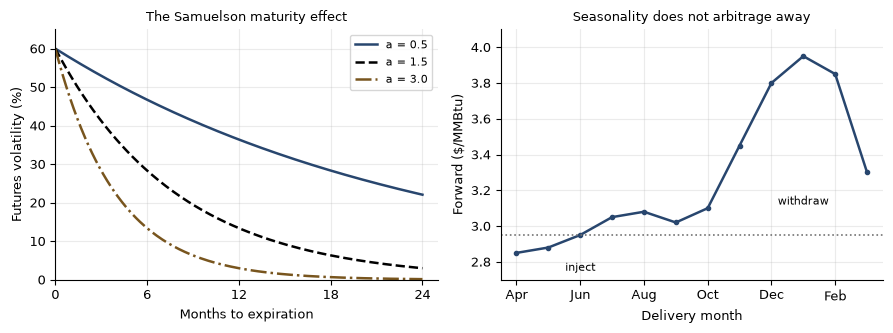

In [4]:
# Figure 36.1. Left: equation (36.2) at sigma_S = 60%. Right: Section 36.2's gas curve.
GAS_CURVE = np.array([2.85, 2.88, 2.95, 3.05, 3.08, 3.02, 3.10, 3.45, 3.80, 3.95, 3.85, 3.30])
MONTHS = ["Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.0, 3.4))
tau = np.linspace(0.0, 24.0, 200)
for a, color, ls in ((0.5, BLUE, "-"), (1.5, "black", "--"), (3.0, AMBER, "-.")):
    ax1.plot(tau, 100 * sigma_F(tau / 12.0, a), color=color, ls=ls, lw=1.8, label="a = %.1f" % a)
ax1.set_xlim(0, 25)
ax1.set_ylim(0, 65)
ax1.set_xticks([0, 6, 12, 18, 24])
ax1.set_xlabel("Months to expiration")
ax1.set_ylabel("Futures volatility (%)")
ax1.set_title("The Samuelson maturity effect", fontsize=9)
ax1.legend(fontsize=8)

ax2.plot(range(1, 13), GAS_CURVE, color=BLUE, lw=1.8, marker="o", ms=3)
ax2.axhline(2.95, color="0.45", ls=":", lw=1.2)
ax2.set_xticks(range(1, 13, 2))
ax2.set_xticklabels(MONTHS[::2])
ax2.set_xlim(0.5, 12.5)
ax2.set_ylim(2.7, 4.1)
ax2.set_xlabel("Delivery month")
ax2.set_ylabel("Forward ($/MMBtu)")
ax2.set_title("Seasonality does not arbitrage away", fontsize=9)
ax2.text(3, 2.75, "inject", ha="center", fontsize=8)
ax2.text(10, 3.12, "withdraw", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

## 4. 尖峰模型对照匹配的对数正态：例 36.3

式 (36.3)：平常日子的价格服从对数正态，中位数 $m = 43$ 美元、对数标准差 $\sigma = 30\%$；有 2.4% 的日子
（$p$，一年约 9 天）价格再乘以一个对数正态的尖峰因子 $J$，其均值 $E[J] = 5$、对数标准差 $s_J = 60\%$。
因此价格是两个对数正态的混合：以概率 $1-p$，$\ln P \sim N(\ln m, \sigma^2)$；以概率 $p$，
$\ln P \sim N(\ln m + \mu_J, \sigma^2 + s_J^2)$，其中 $\mu_J = \ln E[J] - s_J^2/2$。其均值为

$$E[P] = m\,e^{\sigma^2/2}\bigl(1 - p + p\,E[J]\bigr),$$

而第 $q$ 分位数满足

$$(1 - p)\,N\!\left(\frac{\ln(x_q/m)}{\sigma}\right) + p\,N\!\left(\frac{\ln(x_q/m) - \mu_J}{\sqrt{\sigma^2 + s_J^2}}\right) = q,$$

它恰有一个根而没有闭式解，因此用二分法求出。匹配的对数正态与它均值、标准差都相同，
其对数波动率为 $\sqrt{\ln(1 + \text{sd}^2/\text{mean}^2)}$。两者在均值与 99% 分位数上一致，
而在远端尾部分道扬镳：99.9% 分位数上是 573.80 美元对 349.60 美元。

In [5]:
P_SPK, M_SPK, SIG_SPK = 0.024, 43.0, 0.30    # Example 36.3: spike probability, median, log s.d.
EJ, S_J = 5.0, 0.60                              # mean spike factor and its log s.d.
MU_J = log(EJ) - S_J ** 2 / 2                    # so that E[J] = exp(mu_J + s_J^2 / 2) = 5
V_SPK = sqrt(SIG_SPK ** 2 + S_J ** 2)            # a spike day's total log s.d.

# Equation (36.3) as a mixture of two lognormals: (weight, mean of ln P, s.d. of ln P).
SPIKE = [(1 - P_SPK, log(M_SPK), SIG_SPK), (P_SPK, log(M_SPK) + MU_J, V_SPK)]


def mix_moment(comps, k):
    """E[P^k] for a mixture of lognormals."""
    return sum(w * exp(k * mu + 0.5 * k * k * s * s) for w, mu, s in comps)


def mix_cdf(x, comps):
    return sum(w * N((log(x) - mu) / s) for w, mu, s in comps)


def mix_quantile(q, comps):
    """The q-th percentile, by bisection on ln x: the distribution function rises once from 0 to 1."""
    return exp(bisect(lambda y: mix_cdf(exp(y), comps) - q, -10.0, 15.0))


def mix_call(K, comps):
    """Equation (36.4): each regime is one Black call, at that regime's mean and log s.d."""
    return sum(w * black(exp(mu + 0.5 * s * s), K, s)[0] for w, mu, s in comps)


mean_spk = mix_moment(SPIKE, 1)
sd_spk = sqrt(mix_moment(SPIKE, 2) - mean_spk ** 2)
S_LN = sqrt(log(1 + (sd_spk / mean_spk) ** 2))   # the lognormal with the same mean and s.d.
LOGN = [(1.0, log(mean_spk) - 0.5 * S_LN ** 2, S_LN)]

show("mean, m e^{sigma^2/2} (1 - p + p E[J])", M_SPK * exp(SIG_SPK ** 2 / 2) * (1 - P_SPK + P_SPK * EJ), 49.30, 5e-3)
show("mean, as the mixture's first moment", mean_spk, 49.30, 5e-3)
show("standard deviation, spike model", sd_spk, 40.42, 5e-3)
show("matched lognormal: mean", mix_moment(LOGN, 1), 49.30, 5e-3)
show("matched lognormal: standard deviation", sqrt(mix_moment(LOGN, 2) - mix_moment(LOGN, 1) ** 2), 40.42, 5e-3)
show("matched lognormal volatility, %", 100 * S_LN, 71.7, 0.05)
print()
print("%-18s %12s %12s" % ("", "spike model", "lognormal"))
for name, q, a, b in (("median", 0.5, 43.39, 38.12), ("99th percentile", 0.99, 206.81, 202.15),
                      ("99.9th percentile", 0.999, 573.80, 349.60)):
    xa, xb = mix_quantile(q, SPIKE), mix_quantile(q, LOGN)
    print("%-18s %12.2f %12.2f" % (name, xa, xb))
    show("  spike model, %s" % name, xa, a, 5e-3)
    show("  lognormal, %s" % name, xb, b, 5e-3)

mean, m e^{sigma^2/2} (1 - p + p E[J])                  49.2972   book     49.3000   ok
mean, as the mixture's first moment                     49.2972   book     49.3000   ok
standard deviation, spike model                         40.4234   book     40.4200   ok
matched lognormal: mean                                 49.2972   book     49.3000   ok
matched lognormal: standard deviation                   40.4234   book     40.4200   ok
matched lognormal volatility, %                         71.7115   book     71.7000   ok

                    spike model    lognormal
median                    43.39        38.12
  spike model, median                                   43.3857   book     43.3900   ok
  lognormal, median                                     38.1201   book     38.1200   ok
99th percentile          206.81       202.15
  spike model, 99th percentile                         206.8106   book    206.8100   ok
  lognormal, 99th percentile                           202.1478   book  

## 5. 每日上限期权：例 36.3 续

一份支付 $\max(P - K, 0)$ 的每日上限期权，按当天是否出现尖峰条件化估值，即式 (36.4)，未贴现：

$$c(K) = (1 - p)\,c^{\text{B}}\bigl(F_0, K, \sigma\bigr) + p\,c^{\text{B}}\Bigl(E[J]\,F_0,\; K,\; \sqrt{\sigma^2 + s_J^2}\Bigr), \qquad F_0 = m\,e^{\sigma^2/2}.$$

在 $K = 100$ 时，平常日子值 0.0238，尖峰日值 130.24，因此这份上限期权 99% 的价值来自一年中约 9 天。
匹配的对数正态只是一次布莱克公式，远期 49.30 美元、波动率 71.7%。它对平值附近的上限期权定价过高、
对远虚值的定价过低，执行价为 400 美元时相差十倍。

In [6]:
# Equation (36.4) at K = 100, one regime at a time.
F0_SPK = M_SPK * exp(SIG_SPK ** 2 / 2)           # an ordinary day's mean
c_ord = black(F0_SPK, 100.0, SIG_SPK)[0]
c_spk = black(EJ * F0_SPK, 100.0, V_SPK)[0]
show("F0 = 43 e^{0.045}", F0_SPK, 44.98, 5e-3)
show("ordinary day: c_B(44.98, 100, 0.30)", c_ord, 0.0238, 5e-5)
show("spike day: mean E[J] F0", EJ * F0_SPK, 224.90, 5e-3)
show("spike day: total volatility, %", 100 * V_SPK, 67.1, 0.05)
show("spike day: c_B(224.90, 100, 0.671)", c_spk, 130.24, 5e-3)
show("0.976 x ordinary", (1 - P_SPK) * c_ord, 0.0232, 5e-5)
show("0.024 x spike", P_SPK * c_spk, 3.1257, 5e-5)
show("c(100)", (1 - P_SPK) * c_ord + P_SPK * c_spk, 3.1490, 5e-5)
show("share of c(100) from spike days, %", 100 * P_SPK * c_spk / mix_call(100.0, SPIKE), 99.0, 0.5)

print()
print("%6s %12s %12s %8s" % ("strike", "spike model", "lognormal", "ratio"))
for K, a, b, rt in ((60, 5.3300, 10.4989, 0.51), (100, 3.1490, 4.1344, 0.76),
                    (200, 1.6578, 0.6518, 2.54), (400, 0.5056, 0.0483, 10.48),
                    (800, 0.0739, 0.0016, 46.70)):
    ca, cb = mix_call(K, SPIKE), mix_call(K, LOGN)
    print("%6d %12.4f %12.4f %8.2f" % (K, ca, cb, ca / cb))
    show("  cap at %d, spike model" % K, ca, a, 5e-5)
    show("  cap at %d, matched lognormal" % K, cb, b, 5e-5)
    show("  cap at %d, ratio" % K, ca / cb, rt, 5e-3)

F0 = 43 e^{0.045}                                       44.9792   book     44.9800   ok
ordinary day: c_B(44.98, 100, 0.30)                      0.0238   book      0.0238   ok
spike day: mean E[J] F0                                224.8960   book    224.9000   ok
spike day: total volatility, %                          67.0820   book     67.1000   ok
spike day: c_B(224.90, 100, 0.671)                     130.2394   book    130.2400   ok
0.976 x ordinary                                         0.0232   book      0.0232   ok
0.024 x spike                                            3.1257   book      3.1257   ok
c(100)                                                   3.1490   book      3.1490   ok
share of c(100) from spike days, %                      99.2619   book     99.0000   ok

strike  spike model    lognormal    ratio
    60       5.3300      10.4989     0.51
  cap at 60, spike model                                 5.3300   book      5.3300   ok
  cap at 60, matched lognormal     

## 6. 每日上限期权序列对照月度上限期权：例 36.4

一个 30 天的月份，执行价 60 美元，每天 1 MWh，每天的价格都按例 36.3 的尖峰模型抽取。
这一每日上限期权序列支付 $\sum_d \max(P_d - 60, 0)$，无论各天之间是什么关系，它都恰好值 $30\,c(60) = 159.90$ 美元。
以月平均价为标的的上限期权支付 $30\max(\bar P - 60, 0)$，取决于尖峰在时间上如何分布，因此用模拟估值。
尖峰或者出现在相互独立的日子里，或者以连续 $L = 3$ 天、$L = 5$ 天的事件出现（单日出现时 $L = 1$）；一个事件在某一天开始的概率为
$q = 1 - (1-p)^{1/L}$，这使任意一天出现尖峰的概率保持为 2.4%。每个尖峰日各自抽取尖峰因子 $J$。

本书每一行用了 400,000 个月份、种子 36；本单元同样如此，但 NumPy 的生成器与本书所用的随机数序列不同，
因此数字只在抽样误差之内吻合，而不是逐位吻合。本单元还用同一批路径重新估计这一每日上限期权序列与尖峰频率，
无论 $L$ 取多少，它们都应落在 159.90 与 2.4% 上。最后四行是正文所依据的比值：这一每日上限期权序列约为单日情形下
月度上限期权的八倍；五天一簇使月度上限期权增加到三倍以上；而把各天当作独立来定价，得到的价值不到三天一簇时的一半、
不到五天一簇时的三分之一。

In [7]:
DAYS, K_M = 30, 60.0                              # Example 36.4: a 30-day month, strike 60, 1 MWh a day
strip = DAYS * mix_call(K_M, SPIKE)
show("daily strip, 30 x c(60)", strip, 159.90, 5e-3)
show("one spike day's lift to a 30-day average, $", (EJ - 1) * F0_SPK / DAYS, 6.0, 0.05)

rng = np.random.default_rng(36)
N_MONTHS, CHUNK = 400_000, 50_000


def simulate_months(L, n):
    """n months of daily prices, spikes arriving in episodes of L consecutive days.

    An episode starts on a day with probability q = 1 - (1 - p)^(1/L), and a day spikes if an
    episode started on it or on any of the L - 1 days before it, so every day still spikes
    with probability p = 2.4% and the strip is unchanged. Each spike day draws its own factor J.
    """
    q = 1 - (1 - P_SPK) ** (1.0 / L)
    starts = rng.random((n, DAYS + L - 1)) < q
    c = np.concatenate([np.zeros((n, 1), dtype=int), np.cumsum(starts, axis=1)], axis=1)
    spike = (c[:, L:L + DAYS] - c[:, :DAYS]) > 0
    price = M_SPK * np.exp(SIG_SPK * rng.standard_normal((n, DAYS)))
    jump = np.exp(MU_J + S_J * rng.standard_normal((n, DAYS)))
    return np.where(spike, price * jump, price), spike


block = {}
for L, sd_book, cap_book in ((1, 7.38, 19.1), (3, 10.12, 44.3), (5, 12.18, 66.2)):
    s_avg = s_avg2 = s_pay = s_pay2 = s_strip = s_spk = 0.0
    for _ in range(N_MONTHS // CHUNK):
        P, spk = simulate_months(L, CHUNK)
        avg = P.mean(axis=1)
        pay = DAYS * np.maximum(avg - K_M, 0.0)
        s_avg += avg.sum()
        s_avg2 += (avg * avg).sum()
        s_pay += pay.sum()
        s_pay2 += (pay * pay).sum()
        s_strip += np.maximum(P - K_M, 0.0).sum()
        s_spk += spk.mean(axis=1).sum()
    mean_avg = s_avg / N_MONTHS
    sd_avg = sqrt((s_avg2 - N_MONTHS * mean_avg ** 2) / (N_MONTHS - 1))
    cap = s_pay / N_MONTHS
    se_cap = sqrt((s_pay2 / N_MONTHS - cap ** 2) / N_MONTHS)
    block[L] = cap
    print("episodes of %d day(s), %d months" % (L, N_MONTHS))
    sim("  share of days that spike, %", 100 * s_spk / N_MONTHS, 2.4)
    sim("  daily strip (exact value 159.90)", s_strip / N_MONTHS, 159.90)
    sim("  s.d. of the monthly average, $", sd_avg, sd_book)
    sim("  monthly-average cap, $", cap, cap_book, se_cap)

print()
sim("daily strip / monthly cap, single days", strip / block[1], 159.90 / 19.1)
sim("five-day / single-day monthly cap", block[5] / block[1], 66.2 / 19.1)
sim("single-day / three-day monthly cap", block[1] / block[3], 19.1 / 44.3)
sim("single-day / five-day monthly cap", block[1] / block[5], 19.1 / 66.2)

daily strip, 30 x c(60)                                159.8992   book    159.9000   ok
one spike day's lift to a 30-day average, $              5.9972   book      6.0000   ok


episodes of 1 day(s), 400000 months
  share of days that spike, %                            2.4019   book      2.4000   
  daily strip (exact value 159.90)                     160.6632   book    159.9000   
  s.d. of the monthly average, $                         7.4309   book      7.3800   
  monthly-average cap, $                                19.3966   book     19.1000   (+1.9 s.e.)


episodes of 3 day(s), 400000 months
  share of days that spike, %                            2.3967   book      2.4000   
  daily strip (exact value 159.90)                     159.5628   book    159.9000   
  s.d. of the monthly average, $                        10.1118   book     10.1200   
  monthly-average cap, $                                44.2032   book     44.3000   (-0.4 s.e.)


episodes of 5 day(s), 400000 months
  share of days that spike, %                            2.4009   book      2.4000   
  daily strip (exact value 159.90)                     160.0162   book    159.9000   
  s.d. of the monthly average, $                        12.1836   book     12.1800   
  monthly-average cap, $                                66.3076   book     66.2000   (+0.3 s.e.)

daily strip / monthly cap, single days                   8.2437   book      8.3717   
five-day / single-day monthly cap                        3.4185   book      3.4660   
single-day / three-day monthly cap                       0.4388   book      0.4312   
single-day / five-day monthly cap                        0.2925   book      0.2885   


## 7. 发电厂是一份交换期权：例 36.5

一座燃气电厂每 MWh 赚 $\max(P_e - \text{HR}\cdot P_g, 0)$，因此每个小时都是一份 Margrabe 期权：
用 HR 单位的天然气换一 MWh 电力。以远期计且不贴现，它就是以电力远期为标的、以燃料成本为执行价的布莱克看涨期权，
价差波动率为

$$\sigma = \sqrt{\sigma_e^2 + \sigma_g^2 - 2\rho\,\sigma_e\sigma_g}.$$

电力 42.00 美元/MWh，天然气 3.20 美元/MMBtu，热耗率 12.5，6 个月，波动率分别为 55% 与 45%。
高相关性使价差期权便宜：把两端当作独立会把它高估 133%。3-2-1 裂解价差把汽油与取暖油按每桶 42 加仑换算成美元/桶。

In [8]:
FP, GAS_P, HR = 42.0, 3.20, 12.5                  # Example 36.5: power, gas, heat rate
T_SP, SIG_P, SIG_G = 0.5, 0.55, 0.45
FG = GAS_P * HR                                   # fuel cost per MWh


def margrabe(F1, F2, s1, s2, rho, T):
    """Margrabe's exchange option on forwards, undiscounted: Black's call on F1 struck at F2."""
    s = sqrt(s1 ** 2 + s2 ** 2 - 2 * rho * s1 * s2)
    return black(F1, F2, s * sqrt(T))[0], s


show("fuel cost per MWh, 3.20 x 12.5", FG, 40.00, 5e-3)
show("intrinsic spread", FP - FG, 2.00, 5e-3)
print()
print("%5s %14s %13s %11s" % ("rho", "effective vol", "option value", "time value"))
spark = {}
for rho, ve, val in ((0.9, 24.4, 3.929), (0.7, 39.8, 5.658), (0.5, 50.7, 6.891),
                     (0.3, 59.7, 7.900), (0.0, 71.1, 9.171)):
    c, s = margrabe(FP, FG, SIG_P, SIG_G, rho, T_SP)
    spark[rho] = c
    print("%5.1f %13.1f%% %13.3f %11.3f" % (rho, 100 * s, c, c - (FP - FG)))
    show("  rho = %.1f: effective vol, %%" % rho, 100 * s, ve, 0.05)
    show("  rho = %.1f: option value" % rho, c, val, 5e-4)
    show("  rho = %.1f: time value" % rho, c - (FP - FG), val - 2.0, 5e-4)
show("independence overvalues by, %", 100 * (spark[0.0] / spark[0.9] - 1), 133, 0.5)

print()
CRUDE, GASOLINE, HEATING_OIL, GAL_PER_BBL = 78.00, 2.45, 2.60, 42
gas_bbl, ho_bbl = GASOLINE * GAL_PER_BBL, HEATING_OIL * GAL_PER_BBL
show("gasoline, $/bbl", gas_bbl, 102.90, 5e-3)
show("heating oil, $/bbl", ho_bbl, 109.20, 5e-3)
show("3-2-1 crack, $/bbl", (2 * gas_bbl + ho_bbl - 3 * CRUDE) / 3, 27.00, 5e-3)

fuel cost per MWh, 3.20 x 12.5                          40.0000   book     40.0000   ok
intrinsic spread                                         2.0000   book      2.0000   ok

  rho  effective vol  option value  time value
  0.9          24.4%         3.929       1.929
  rho = 0.9: effective vol, %                           24.3926   book     24.4000   ok
  rho = 0.9: option value                                3.9294   book      3.9290   ok
  rho = 0.9: time value                                  1.9294   book      1.9290   ok
  0.7          39.8%         5.658       3.658
  rho = 0.7: effective vol, %                           39.8121   book     39.8000   ok
  rho = 0.7: option value                                5.6577   book      5.6580   ok
  rho = 0.7: time value                                  3.6577   book      3.6580   ok
  0.5          50.7%         6.891       4.891
  rho = 0.5: effective vol, %                           50.7445   book     50.7000   ok
  rho = 0.5: option

## 8. 仓储的内在价值与外在价值：例 36.6

根据第 36.2 节的曲线，一座仓储设施今天就可以锁定一个价差：在五个最便宜的月份注入（4 月至 9 月，跳过 8 月），
在五个最贵的月份采出（11 月至次年 3 月）。内在价值是两个平均值之差，每个周期每 MMBtu 0.72 美元。

**外在价值占比表**。本章把日历价差期权序列按一份交换期权（Margrabe 公式）估值：标的是平均采出价对平均注入价，
期限 6 个月，两端波动率均取表中所示的波动率，二者的相关系数为 $\rho$；占比等于期权价值减去内在价值 0.72 美元，再除以期权价值。
下面的单元重算全部十二项。这是一个闭式近似：要为设施本身估值，需要第 36.5 节所说的、在价格与库存上进行的动态规划，
或者第 20 章的最小二乘蒙特卡洛。

In [9]:
order = np.argsort(GAS_CURVE)                     # Example 36.6, off Section 36.2's curve
inject, withdraw = sorted(order[:5]), sorted(order[-5:])
print("inject:  ", ", ".join(MONTHS[i] for i in inject))
print("withdraw:", ", ".join(MONTHS[i] for i in withdraw))
show("five cheapest months, average", GAS_CURVE[inject].mean(), 2.95, 5e-3)
show("five dearest months, average", GAS_CURVE[withdraw].mean(), 3.67, 5e-3)
show("intrinsic value per MMBtu per cycle", GAS_CURVE[withdraw].mean() - GAS_CURVE[inject].mean(), 0.72, 5e-3)

# Example 36.6's table: one Margrabe exchange option on the two averages, six months, both legs at the volatility shown
f_wd, f_in = GAS_CURVE[withdraw].mean(), GAS_CURVE[inject].mean()
STORE_TABLE = {(30, 0.90): 0.2, (30, 0.75): 2.2, (30, 0.50): 7.1,
               (45, 0.90): 1.7, (45, 0.75): 8.3, (45, 0.50): 17.4,
               (60, 0.90): 5.1, (60, 0.75): 15.7, (60, 0.50): 27.0,
               (80, 0.90): 11.0, (80, 0.75): 25.0, (80, 0.50): 37.4}
for (vol, rho), printed in sorted(STORE_TABLE.items()):
    v_total = vol / 100.0 * sqrt(2.0 * (1.0 - rho) * 0.5)    # spread volatility times sqrt(T), T = 0.5
    c_store = black(f_wd, f_in, v_total)[0]
    show("extrinsic share, vol %d%%, rho %.2f, %%" % (vol, rho), 100.0 * (c_store - (f_wd - f_in)) / c_store, printed, 0.05)

inject:   Apr, May, Jun, Jul, Sep
withdraw: Nov, Dec, Jan, Feb, Mar
five cheapest months, average                            2.9500   book      2.9500   ok
five dearest months, average                             3.6700   book      3.6700   ok
intrinsic value per MMBtu per cycle                      0.7200   book      0.7200   ok
extrinsic share, vol 30%, rho 0.50, %                    7.0684   book      7.1000   ok
extrinsic share, vol 30%, rho 0.75, %                    2.1672   book      2.2000   ok
extrinsic share, vol 30%, rho 0.90, %                    0.1574   book      0.2000   ok
extrinsic share, vol 45%, rho 0.50, %                   17.4317   book     17.4000   ok
extrinsic share, vol 45%, rho 0.75, %                    8.2748   book      8.3000   ok
extrinsic share, vol 45%, rho 0.90, %                    1.7267   book      1.7000   ok
extrinsic share, vol 60%, rho 0.50, %                   27.0313   book     27.0000   ok
extrinsic share, vol 60%, rho 0.75, %               

## 9. 日历价差为什么需要两个因子：例 36.7

市场服从 $\ln S = \chi + \xi$：短期因子以 $\kappa = 2$ 回复、$\sigma_\chi = 40\%$；长期因子是随机游走、
$\sigma_\xi = 20\%$；两者独立。期货波动率为 $\sigma_F(\tau) = \sqrt{\sigma_\chi^2 e^{-2\kappa\tau} + \sigma_\xi^2}$。
用单因子 $\sigma e^{-a\tau}$ 拟合一年期与两年期合约，需要 $a = 0.035$、$\sigma = 21.5\%$。

期权在 $T_0 = 0.5$ 到期，收取两年期合约（$T_2 = 2$）、交付一年期合约（$T_1 = 1$），两者都是 80 美元。
长期因子从 $\ln(F_2/F_1)$ 中消去，因此

$$v^2 = \sigma_\chi^2 \bigl(e^{-\kappa T_1} - e^{-\kappa T_2}\bigr)^2\,\frac{e^{2\kappa T_0} - 1}{2\kappa},$$

两个远期相等时 Margrabe 公式化为 $80\,[2N(v/2) - 1]$，这是远期价值。单因子模型用同一个公式，只把参数换成
$\sigma$ 与 $a$，得到的价值约为双因子价格的十二分之一，尽管双因子模型中两端的瞬时相关系数仍有 0.974（在期权存续期内为 0.927）。

In [10]:
SX, KAP, SL = 0.40, 2.0, 0.20                     # Example 36.7: short-term vol, its reversion, long-term vol
F_CAL, T0, T1, T2 = 80.0, 0.5, 1.0, 2.0


def vol_2f(tau):
    """The two-factor futures volatility at time to delivery tau."""
    return np.sqrt(SX ** 2 * np.exp(-2 * KAP * tau) + SL ** 2)


# The one-factor fit sigma e^{-a tau} through the one- and two-year contracts.
A1 = log(vol_2f(T1) / vol_2f(T2)) / (T2 - T1)
S1 = vol_2f(T1) * exp(A1 * T1)
show("one-factor fit: a", A1, 0.035, 5e-4)
show("one-factor fit: sigma, %", 100 * S1, 21.5, 0.05)
print()
print("%7s %12s %12s" % ("months", "two-factor", "one-factor"))
for m, two, one in ((1, 39.3, 21.4), (6, 24.8, 21.1), (12, 20.7, 20.7), (24, 20.0, 20.0)):
    v2, v1 = 100 * vol_2f(m / 12.0), 100 * S1 * exp(-A1 * m / 12.0)
    print("%7d %11.1f%% %11.1f%%" % (m, v2, v1))
    show("  %2d months, two-factor, %%" % m, v2, two, 0.05)
    show("  %2d months, one-factor, %%" % m, v1, one, 0.05)


def spread_v(sig, k):
    """Total s.d. of ln(F2/F1) to T0 when one mean-reverting factor drives both legs."""
    return sqrt(sig ** 2 * (exp(-k * T1) - exp(-k * T2)) ** 2 * (exp(2 * k * T0) - 1) / (2 * k))


v_two, v_one = spread_v(SX, KAP), spread_v(S1, A1)
c_two, c_one = F_CAL * (2 * N(v_two / 2) - 1), F_CAL * (2 * N(v_one / 2) - 1)
print()
show("two-factor: v, %", 100 * v_two, 5.92, 5e-3)
show("one-factor: v, %", 100 * v_one, 0.50, 5e-3)
show("two-factor option value", c_two, 1.89, 5e-3)
show("one-factor option value", c_one, 0.16, 5e-3)
show("80[2N(v/2) - 1] is Black at F = K (two-factor)", black(F_CAL, F_CAL, v_two)[0], c_two, 1e-10)
show("ratio ('about a twelfth')", c_two / c_one, 12.0, 0.5)
rho_legs = (SX ** 2 * exp(-KAP * (T1 + T2)) + SL ** 2) / (vol_2f(T1) * vol_2f(T2))
show("two-factor correlation of the legs", rho_legs, 0.974, 5e-4)

one-factor fit: a                                        0.0347   book      0.0350   ok
one-factor fit: sigma, %                                21.4509   book     21.5000   ok

 months   two-factor   one-factor
      1        39.3%        21.4%
   1 months, two-factor, %                              39.3249   book     39.3000   ok
   1 months, one-factor, %                              21.3890   book     21.4000   ok
      6        24.8%        21.1%
   6 months, two-factor, %                              24.8302   book     24.8000   ok
   6 months, one-factor, %                              21.0821   book     21.1000   ok
     12        20.7%        20.7%
  12 months, two-factor, %                              20.7197   book     20.7000   ok
  12 months, one-factor, %                              20.7197   book     20.7000   ok
     24        20.0%        20.0%
  24 months, two-factor, %                              20.0134   book     20.0000   ok
  24 months, one-factor, %           

## 10. 品级、地点与时点：例 36.8

一家生产商以 78.00 美元的轻质低硫原油合约为基准，经品级、地点与时点调整后的实现价格，以及对冲绝对价格之后剩下的风险。
未对冲的标准差是绝对价格的 32%；对冲后的标准差是 5.95 美元基差的 28%。

In [11]:
FLAT = 78.00                                      # Example 36.8: contract price
GRADE, LOCATION, TIMING = -3.20, -2.40, -0.35
realized = FLAT + GRADE + LOCATION + TIMING
basis = realized - FLAT
show("realized price, $/bbl", realized, 72.05, 5e-3)
show("total basis, $/bbl", basis, -5.95, 5e-3)
show("total basis, % of the contract", -100 * basis / FLAT, 7.6, 0.05)
sd_unhedged, sd_hedged = 0.32 * FLAT, 0.28 * -basis
show("unhedged s.d. (32% of the flat price), $/bbl", sd_unhedged, 24.96, 5e-3)
show("hedged s.d. (28% of the basis), $/bbl", sd_hedged, 1.67, 5e-3)
show("risk reduction, %", 100 * (1 - sd_hedged / sd_unhedged), 93.3, 0.05)

realized price, $/bbl                                   72.0500   book     72.0500   ok
total basis, $/bbl                                      -5.9500   book     -5.9500   ok
total basis, % of the contract                           7.6282   book      7.6000   ok
unhedged s.d. (32% of the flat price), $/bbl            24.9600   book     24.9600   ok
hedged s.d. (28% of the basis), $/bbl                    1.6660   book      1.6700   ok
risk reduction, %                                       93.3253   book     93.3000   ok


## 11. 堆叠与展期：例 36.9

某供应商以固定价格卖出 10 年的交付量，每年 100 万桶，全部按 78 美元堆叠在近月：7.8 亿美元的堆叠。
每月展期的成本是整个堆叠上的月度期货升水，一年十二次。

保证金时点方面，价格下跌使期货当即以现金损失全部金额，而供应合同上的利得在 10 年中每年到账十分之一。
本章把每年的利得从年中按 5% 连续复利贴现：

$$\text{PV} = \frac{\text{损失}}{10}\sum_{k=1}^{10} e^{-0.05\,(k - 1/2)},$$

它是现金损失的 79%。最后一行是例 36.2 的 Samuelson 比值，即本章所说的“约为四倍”。
金额以百万美元计，因此 61.4 即本章的 6140 万美元，122.7 即 1.227 亿美元。

In [12]:
BBL, PRICE, YEARS, R_ST = 10e6, 78.0, 10, 0.05    # Example 36.9
stack = BBL * PRICE / 1e6                         # $m
show("stack ratio, 10m bbl / 1m bbl", BBL / 1e6, 10, 1e-9)
show("stack, $m", stack, 780, 1e-9)
print()
print("%16s %11s %16s" % ("monthly contango", "per year", "cost/yr ($m)"))
for c, ann, cost in ((0.005, 6.0, 46.8), (0.01, 12.0, 93.6), (0.02, 24.0, 187.2)):
    a = 12 * c
    print("%15.1f%% %10.1f%% %16.1f" % (100 * c, 100 * a, stack * a))
    show("  %.1f%% a month: per year, %%" % (100 * c), 100 * a, ann, 0.05)
    show("  %.1f%% a month: cost per year, $m" % (100 * c), stack * a, cost, 0.05)

# Each year's gain on the supply contract arrives at mid-year, discounted at 5% continuous.
annuity = sum(exp(-R_ST * (k - 0.5)) for k in range(1, YEARS + 1))
print()
print("%10s %16s %16s" % ("price fall", "futures ($m)", "PV gain ($m)"))
for fall, loss, pv in ((0.10, 78.0, 61.4), (0.20, 156.0, 122.7), (0.30, 234.0, 184.1),
                       (0.40, 312.0, 245.5)):
    gain = (BBL / YEARS) * PRICE * fall / 1e6 * annuity
    print("%9d%% %16.1f %16.1f" % (-100 * fall, stack * fall, gain))
    show("  -%d%%: futures loss, $m" % (100 * fall), stack * fall, loss, 0.05)
    show("  -%d%%: PV of the contract gain, $m" % (100 * fall), gain, pv, 0.05)
show("PV of gain / cash loss, %", 100 * annuity / YEARS, 79, 0.5)
show("Samuelson: front / twelve-month vol at a = 1.5", ratio_sam, 4.0, 0.1)

stack ratio, 10m bbl / 1m bbl                           10.0000   book     10.0000   ok
stack, $m                                              780.0000   book    780.0000   ok

monthly contango    per year     cost/yr ($m)
            0.5%        6.0%             46.8
  0.5% a month: per year, %                              6.0000   book      6.0000   ok
  0.5% a month: cost per year, $m                       46.8000   book     46.8000   ok
            1.0%       12.0%             93.6
  1.0% a month: per year, %                             12.0000   book     12.0000   ok
  1.0% a month: cost per year, $m                       93.6000   book     93.6000   ok
            2.0%       24.0%            187.2
  2.0% a month: per year, %                             24.0000   book     24.0000   ok
  2.0% a month: cost per year, $m                      187.2000   book    187.2000   ok

price fall     futures ($m)     PV gain ($m)
      -10%             78.0             61.4
  -10%: futures loss

## 12. 一个没有仓储成本的可储存资产：例 36.10

配额可以无成本地结转，因此 $u = y = 0$，式 (36.1) 化为 $F = S e^{rT}$，这里现货 72.00 欧元、利率 3.5%。
若各期限的远期都比持有成本低 3%，隐含便利收益就是 $-\ln(0.97)/T$：一次性损失摊到更长期限上，表现为按 $1/T$ 衰减的收益率，而持续收益率不会衰减。

In [13]:
S_EUA, R_EUA = 72.0, 0.035                       # Example 36.10
for T, want in ((0.5, 73.27), (1, 74.56), (2, 77.22), (3, 79.97)):
    show("forward at %.1f years, F = S e^{rT}" % T, S_EUA * exp(R_EUA * T), want, 5e-3)
print()
for T, want in ((0.5, 6.09), (1, 3.05), (2, 1.52), (3, 1.02)):
    F = 0.97 * S_EUA * exp(R_EUA * T)             # 3% below full carry
    show("implied y at %.1f years, %%" % T, 100 * implied_y(F, S_EUA, T, R_EUA, 0.0), want, 5e-3)
    show("  ... equals -ln(0.97) / T, %", -100 * log(0.97) / T, want, 5e-3)

forward at 0.5 years, F = S e^{rT}                      73.2711   book     73.2700   ok
forward at 1.0 years, F = S e^{rT}                      74.5646   book     74.5600   ok
forward at 2.0 years, F = S e^{rT}                      77.2206   book     77.2200   ok
forward at 3.0 years, F = S e^{rT}                      79.9712   book     79.9700   ok

implied y at 0.5 years, %                                6.0918   book      6.0900   ok
  ... equals -ln(0.97) / T, %                            6.0918   book      6.0900   ok
implied y at 1.0 years, %                                3.0459   book      3.0500   ok
  ... equals -ln(0.97) / T, %                            3.0459   book      3.0500   ok
implied y at 2.0 years, %                                1.5230   book      1.5200   ok
  ... equals -ln(0.97) / T, %                            1.5230   book      1.5200   ok
implied y at 3.0 years, %                                1.0153   book      1.0200   ok
  ... equals -ln(0.97) / T, %  

## 13. 凸的供给曲线遇上垂直的供给曲线：例 36.11

出清价格按表中各点之间的线性插值，从减排成本曲线上读出。同样 2000 万吨的移动，在 1.9 亿吨处使价格上升 15.7%，
在 2.9 亿吨处上升 50%，变化的只是在曲线上的位置。

In [14]:
MERIT_Q = [0, 50, 120, 200, 260, 300, 320]         # Example 36.11: cumulative abatement, Mt
MERIT_P = [0, 8, 25, 45, 70, 110, 190]              # marginal cost, EUR/t


def clearing(q):
    """The clearing price: linear interpolation on the merit order."""
    return float(np.interp(q, MERIT_Q, MERIT_P))


print("%14s %22s %8s" % ("abatement", "clearing price", "change"))
for q0, q1, p0, p1, ch in ((190, 210, 42.50, 49.17, 15.7), (250, 270, 65.83, 80.00, 21.5),
                           (270, 290, 80.00, 100.00, 25.0), (290, 310, 100.00, 150.00, 50.0)):
    a, b = clearing(q0), clearing(q1)
    print("%5d -> %3d Mt %9.2f -> %8.2f %+7.1f%%" % (q0, q1, a, b, 100 * (b / a - 1)))
    show("  price at %d Mt" % q0, a, p0, 5e-3)
    show("  price at %d Mt" % q1, b, p1, 5e-3)
    show("  change, %", 100 * (b / a - 1), ch, 0.05)

     abatement         clearing price   change
  190 -> 210 Mt     42.50 ->    49.17   +15.7%
  price at 190 Mt                                       42.5000   book     42.5000   ok
  price at 210 Mt                                       49.1667   book     49.1700   ok
  change, %                                             15.6863   book     15.7000   ok
  250 -> 270 Mt     65.83 ->    80.00   +21.5%
  price at 250 Mt                                       65.8333   book     65.8300   ok
  price at 270 Mt                                       80.0000   book     80.0000   ok
  change, %                                             21.5190   book     21.5000   ok
  270 -> 290 Mt     80.00 ->   100.00   +25.0%
  price at 270 Mt                                       80.0000   book     80.0000   ok
  price at 290 Mt                                      100.0000   book    100.0000   ok
  change, %                                             25.0000   book     25.0000   ok
  290 -> 310 Mt    1

## 14. 双峰密度对微笑做了什么：例 36.12

一年期配额价格服从混合分布：以概率 $p = 0.35$ 远期升到 110 欧元，否则为 45 欧元，每个状态内是波动率 25% 的对数正态。
看涨期权按状态条件化定价，即式 (36.5)，按 $r = 3.5\%$ 贴现：

$$c(K) = e^{-rT}\Big[\,p\,c^{\text{B}}(F_h,K,\sigma_w) + (1-p)\,c^{\text{B}}(F_l,K,\sigma_w)\,\Big].$$

每个价格都反解为单一的布莱克波动率。**delta 误差**是混合分布的真实 delta 减去在该拟合波动率下布莱克的 $N(d_1)$，
两者都是远期 delta。真实 delta 保持状态结构不变、让两个状态的远期都与 $F$ 成比例变动，因此等于
$\bigl[p\,N(d_1^h)F_h + (1-p)\,N(d_1^l)F_l\bigr]/F$；只有这样读，那一列才能复现。在所列执行价中，
最大的误差是 100 欧元处的 +0.078。

混合分布的方差是 $(pF_h^2 + (1-p)F_l^2)\,e^{\sigma_w^2} - F^2$，其中状态不确定性 $p(1-p)(F_h - F_l)^2$ 占 73%。

In [15]:
P_HI, F_HI, F_LO, S_REG, R_OPT = 0.35, 110.0, 45.0, 0.25, 0.035   # Example 36.12, one year
F_MIX = P_HI * F_HI + (1 - P_HI) * F_LO
DF = exp(-R_OPT)
show("mixture forward", F_MIX, 67.75, 5e-3)


def mix_price(K):
    """Equation (36.5): a discounted, probability-weighted pair of Black calls."""
    return DF * (P_HI * black(F_HI, K, S_REG)[0] + (1 - P_HI) * black(F_LO, K, S_REG)[0])


def implied_vol(K):
    """The single Black volatility that reproduces the mixture price."""
    c = mix_price(K)
    return bisect(lambda v: DF * black(F_MIX, K, v)[0] - c, 0.01, 3.0)


def delta_error(K):
    """True forward delta (both regime forwards scale with F) minus Black's N(d1) at the fitted vol."""
    true = (P_HI * black(F_HI, K, S_REG)[1] * F_HI + (1 - P_HI) * black(F_LO, K, S_REG)[1] * F_LO) / F_MIX
    return true - black(F_MIX, K, implied_vol(K))[1]


ROWS_CV = ((40, 28.167, 45.5, -0.036), (50, 21.934, 51.1, -0.069), (60, 17.418, 55.0, -0.059),
           (67.75, 14.535, 56.4, -0.026), (80, 10.552, 56.3, 0.034), (90, 7.769, 54.7, 0.067),
           (100, 5.474, 52.6, 0.078), (120, 2.407, 48.4, 0.060))
print("%8s %9s %12s %12s" % ("strike", "call", "implied vol", "delta error"))
for K, c, vol, de in ROWS_CV:
    print("%8.2f %9.3f %11.1f%% %+12.3f" % (K, mix_price(K), 100 * implied_vol(K), delta_error(K)))
print()
for K, c, vol, de in ROWS_CV:
    show("  K = %g: call" % K, mix_price(K), c, 5e-4)
    show("  K = %g: implied vol, %%" % K, 100 * implied_vol(K), vol, 0.05)
    show("  K = %g: delta error" % K, delta_error(K), de, 5e-4)
worst = max(ROWS_CV, key=lambda row: abs(delta_error(row[0])))
show("largest |delta error| over the strikes", abs(delta_error(worst[0])), 0.078, 5e-4)
show("  ... at strike", worst[0], 100, 1e-9)

var_mix = (P_HI * F_HI ** 2 + (1 - P_HI) * F_LO ** 2) * exp(S_REG ** 2) - F_MIX ** 2
var_regime = P_HI * (1 - P_HI) * (F_HI - F_LO) ** 2
V_MATCH = sqrt(log(1 + var_mix / F_MIX ** 2))
print()
show("mixture standard deviation, EUR", sqrt(var_mix), 36.32, 5e-3)
show("variance-matched lognormal vol, %", 100 * V_MATCH, 50.3, 0.05)
show("regime share of the variance, %", 100 * var_regime / var_mix, 73, 0.5)
show("within-regime share of the variance, %", 100 * (1 - var_regime / var_mix), 27, 0.5)

mixture forward                                         67.7500   book     67.7500   ok
  strike      call  implied vol  delta error
   40.00    28.167        45.5%       -0.036
   50.00    21.934        51.1%       -0.069
   60.00    17.418        55.0%       -0.059
   67.75    14.535        56.4%       -0.026


   80.00    10.552        56.3%       +0.034

   90.00     7.769        54.7%       +0.067

  100.00     5.474        52.6%       +0.078
  120.00     2.407        48.4%       +0.060

  K = 40: call                                          28.1672   book     28.1670   ok
  K = 40: implied vol, %                                45.4822   book     45.5000   ok
  K = 40: delta error                                   -0.0361   book     -0.0360   ok
  K = 50: call                                          21.9336   book     21.9340   ok
  K = 50: implied vol, %                                51.0534   book     51.1000   ok
  K = 50: delta error                                   -0.0689   book     -0.0690   ok
  K = 60: call                                          17.4183   book     17.4180   ok
  K = 60: implied vol, %                                54.9821   book     55.0000   ok
  K = 60: delta error                                   -0.0590   book     -0.0590   ok
  K = 67.75: call                                       14.5349   book     14.5350   ok


  K = 67.75: implied vol, %                             56.4318   book     56.4000   ok


  K = 67.75: delta error                                -0.0257   book     -0.0260   ok


  K = 80: call                                          10.5523   book     10.5520   ok
  K = 80: implied vol, %                                56.2599   book     56.3000   ok
  K = 80: delta error                                    0.0343   book      0.0340   ok
  K = 90: call                                           7.7687   book      7.7690   ok


  K = 90: implied vol, %                                54.7110   book     54.7000   ok
  K = 90: delta error                                    0.0665   book      0.0670   ok
  K = 100: call                                          5.4737   book      5.4740   ok
  K = 100: implied vol, %                               52.6274   book     52.6000   ok
  K = 100: delta error                                   0.0778   book      0.0780   ok
  K = 120: call                                          2.4070   book      2.4070   ok
  K = 120: implied vol, %                               48.3856   book     48.4000   ok
  K = 120: delta error                                   0.0603   book      0.0600   ok


largest |delta error| over the strikes                   0.0778   book      0.0780   ok
  ... at strike                                        100.0000   book    100.0000   ok

mixture standard deviation, EUR                         36.3210   book     36.3200   ok
variance-matched lognormal vol, %                       50.2623   book     50.3000   ok
regime share of the variance, %                         72.8607   book     73.0000   ok
within-regime share of the variance, %                  27.1393   book     27.0000   ok


## 15. 图 36.2：两个峰、一个方差，以及驼峰

本单元把本章所画的每一个坐标（每条密度曲线上的 30 个点与 22 个隐含波动率）与公式逐一核对，
再核对正文从图上读出的数字：对数正态的峰高只有混合分布较低那个峰的 61%；在 75 欧元处，对数正态的密度为 0.0095，
而混合分布为 0.0041，填满了混合分布留下的低谷。右图中的水平线是方差匹配的对数正态的 50.26%。

mixture density points that differ (of 30)               0.0000   book      0.0000   ok
lognormal density points that differ (of 30)             0.0000   book      0.0000   ok
implied-vol points that differ (of 22)                   0.0000   book      0.0000   ok
flat variance-matched line, %                           50.2623   book     50.2600   ok

peaks: lognormal at 46.38, mixture's lower peak at 40.99
lognormal peak / mixture lower peak, %                  61.4468   book     61.0000   ok
density at 75: lognormal                                 0.0095   book      0.0095   ok
density at 75: mixture                                   0.0041   book      0.0041   ok
at-the-money implied vol (figure label), %              56.4318   book     56.4000   ok


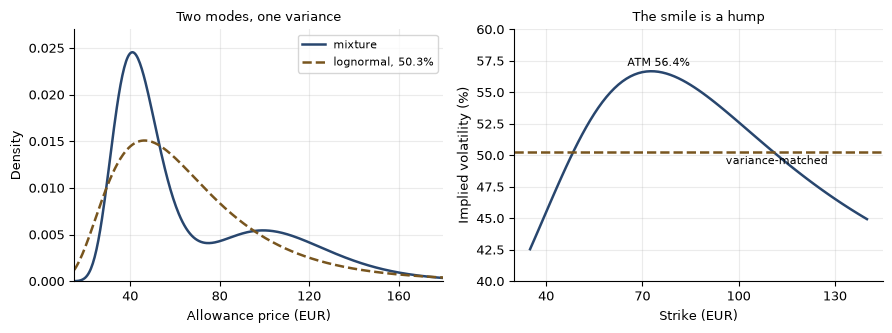

In [16]:
def lognormal_pdf(x, F, v):
    """Density of a lognormal with mean F and log s.d. v."""
    return np.exp(-(np.log(x / F) + 0.5 * v * v) ** 2 / (2 * v * v)) / (x * v * sqrt(2 * pi))


def mixture_pdf(x):
    return P_HI * lognormal_pdf(x, F_HI, S_REG) + (1 - P_HI) * lognormal_pdf(x, F_LO, S_REG)


# Figure 36.2's plotted coordinates, as the chapter prints them.
X_PDF = [15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110,
         115, 120, 125, 130, 135, 140, 150, 160, 170, 180]
BOOK_MIX = [0.00001, 0.00040, 0.00348, 0.01128, 0.02012, 0.02443, 0.02290, 0.01798, 0.01257,
            0.00832, 0.00568, 0.00441, 0.00409, 0.00429, 0.00470, 0.00511, 0.00537, 0.00545,
            0.00533, 0.00505, 0.00464, 0.00416, 0.00365, 0.00314, 0.00265, 0.00220, 0.00147,
            0.00093, 0.00058, 0.00035]
BOOK_LN = [0.00121, 0.00372, 0.00708, 0.01036, 0.01289, 0.01444, 0.01506, 0.01491, 0.01424,
           0.01323, 0.01204, 0.01079, 0.00955, 0.00838, 0.00730, 0.00632, 0.00545, 0.00469,
           0.00402, 0.00345, 0.00295, 0.00252, 0.00216, 0.00184, 0.00158, 0.00135, 0.00099,
           0.00073, 0.00053, 0.00040]
K_SMILE = [35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115, 120, 125,
           130, 135, 140]
BOOK_SMILE = [42.54, 45.48, 48.39, 51.05, 53.29, 54.98, 56.08, 56.60, 56.63, 56.26, 55.59,
              54.71, 53.70, 52.63, 51.53, 50.44, 49.39, 48.39, 47.43, 46.54, 45.71, 44.93]

got_mix, got_ln = mixture_pdf(np.array(X_PDF, float)), lognormal_pdf(np.array(X_PDF, float), F_MIX, V_MATCH)
got_smile = [100 * implied_vol(K) for K in K_SMILE]
bad_mix = [x for x, g, b in zip(X_PDF, got_mix, BOOK_MIX) if abs(g - b) > 5e-6]
bad_ln = [x for x, g, b in zip(X_PDF, got_ln, BOOK_LN) if abs(g - b) > 5e-6]
bad_smile = [K for K, g, b in zip(K_SMILE, got_smile, BOOK_SMILE) if abs(g - b) > 5e-3]
show("mixture density points that differ (of 30)", len(bad_mix), 0, 0)
show("lognormal density points that differ (of 30)", len(bad_ln), 0, 0)
show("implied-vol points that differ (of 22)", len(bad_smile), 0, 0)
for x, g, b in zip(X_PDF, got_mix, BOOK_MIX):
    if x in bad_mix:
        print("    mixture at %d: %.5f against %.5f" % (x, g, b))
for x, g, b in zip(X_PDF, got_ln, BOOK_LN):
    if x in bad_ln:
        print("    lognormal at %d: %.5f against %.5f" % (x, g, b))
for K, g, b in zip(K_SMILE, got_smile, BOOK_SMILE):
    if K in bad_smile:
        print("    执行价 %d 处的隐含波动率：%.2f，对照 %.2f" % (K, g, b))
show("flat variance-matched line, %", 100 * V_MATCH, 50.26, 5e-3)

# The prose under the figure.
grid = np.linspace(20.0, 180.0, 160_001)
low = grid[grid < 70]
mix_mode = low[np.argmax(mixture_pdf(low))]
ln_mode = grid[np.argmax(lognormal_pdf(grid, F_MIX, V_MATCH))]
print()
print("peaks: lognormal at %.2f, mixture's lower peak at %.2f" % (ln_mode, mix_mode))
show("lognormal peak / mixture lower peak, %",
     100 * lognormal_pdf(ln_mode, F_MIX, V_MATCH) / mixture_pdf(mix_mode), 61, 0.5)
show("density at 75: lognormal", lognormal_pdf(75.0, F_MIX, V_MATCH), 0.0095, 5e-5)
show("density at 75: mixture", mixture_pdf(75.0), 0.0041, 5e-5)
show("at-the-money implied vol (figure label), %", 100 * implied_vol(F_MIX), 56.4, 0.05)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.0, 3.4))
xs = np.linspace(15.0, 180.0, 400)
ax1.plot(xs, mixture_pdf(xs), color=BLUE, lw=1.8, label="mixture")
ax1.plot(xs, lognormal_pdf(xs, F_MIX, V_MATCH), color=AMBER, ls="--", lw=1.8,
         label="lognormal, %.1f%%" % (100 * V_MATCH))
ax1.set_xlim(15, 180)
ax1.set_ylim(0, 0.027)
ax1.set_xticks([40, 80, 120, 160])
ax1.set_xlabel("Allowance price (EUR)")
ax1.set_ylabel("Density")
ax1.set_title("Two modes, one variance", fontsize=9)
ax1.legend(fontsize=8)
ks = np.linspace(35.0, 140.0, 85)
ax2.plot(ks, [100 * implied_vol(K) for K in ks], color=BLUE, lw=1.8)
ax2.axhline(100 * V_MATCH, color=AMBER, ls="--", lw=1.8)
ax2.text(75, 57.1, "ATM %.1f%%" % (100 * implied_vol(F_MIX)), ha="center", fontsize=8)
ax2.text(96, 49.3, "variance-matched", fontsize=8)
ax2.set_xlim(30, 145)
ax2.set_ylim(40, 60)
ax2.set_xticks([40, 70, 100, 130])
ax2.set_xlabel("Strike (EUR)")
ax2.set_ylabel("Implied volatility (%)")
ax2.set_title("The smile is a hump", fontsize=9)
plt.tight_layout()
plt.show()

## 16. 没有对冲的定价：例 36.13

某参考气象站 11 月至次年 3 月的 HDD：均值 1200，标准差 140；执行值 1100、每 HDD 赔付 5,000 美元的看跌期权。
该指数接近正态，因此适用巴舍利耶形式，即式 (36.6)，其中 $d = (\mu - K)/\sigma$：

$$P = A\big[\sigma\,\varphi(d) - (\mu - K)\,\Phi(-d)\big], \qquad C = A\big[\sigma\,\varphi(d) + (\mu - K)\,\Phi(d)\big].$$

平价关系 $C - P = A(\mu - K)$ 按结算日计分毫不差地成立；若在今天支付，两边乘以同一个贴现因子。每年 1 个 HDD 的变暖趋势在 30 年窗口上平均之后，
会使均值滞后约 15 个 HDD，按每 HDD 5,000 美元计，对指数呈线性的合约偏差 75,000 美元，这份看跌期权则变动约 19,000 美元，即权利金的五分之一。站点与负荷那张表是最小方差对冲：
方差降低 $\rho^2$，残差标准差是未对冲时的 $\sqrt{1-\rho^2}$。

In [17]:
MU_H, SD_H, K_H, TICK = 1200.0, 140.0, 1100.0, 5000.0     # Example 36.13
d = (MU_H - K_H) / SD_H
put = TICK * (SD_H * phi(d) - (MU_H - K_H) * N(-d))       # equation (36.6)
call = TICK * (SD_H * phi(d) + (MU_H - K_H) * N(d))
show("d = 100 / 140", d, 0.7143, 5e-5)
show("Pr(HDD < 1100) = N(-d), %", 100 * N(-d), 23.8, 0.05)
show("E[1100 - HDD | HDD < 1100]", put / TICK / N(-d), 82.2, 0.05)
show("value of the put, $", put, 97618, 0.5)
show("value of the matching call, $", call, 597618, 0.5)
show("C - P = tick x (mu - K), $", call - put, 500000, 1e-6)

# Detrending: a 1 HDD/yr trend averaged over a 30-year window sits 15 years behind today.
bias = 1.0 * 30 / 2
show("30-year window, 1 HDD/yr trend: bias in mu, HDD", bias, 15, 1e-9)
show("  ... in contract value, $", TICK * bias, 75000, 1e-6)
d_s = (MU_H - bias - K_H) / SD_H
put_s = TICK * (SD_H * phi(d_s) - (MU_H - bias - K_H) * N(-d_s))
show("  ……对这份看跌期权，美元", put_s - put, 19000, 500)

print()
print("%10s %18s %14s" % ("rho", "variance reduced", "residual s.d."))
for rho, vr, res in ((0.95, 90, 31), (0.90, 81, 44), (0.85, 72, 53), (0.70, 49, 71), (0.50, 25, 87)):
    print("%10.2f %17.0f%% %13.0f%%" % (rho, 100 * rho ** 2, 100 * sqrt(1 - rho ** 2)))
    show("  rho = %.2f: variance reduction, %%" % rho, 100 * rho ** 2, vr, 0.5)
    show("  rho = %.2f: residual s.d., %%" % rho, 100 * sqrt(1 - rho ** 2), res, 0.5)

d = 100 / 140                                            0.7143   book      0.7143   ok
Pr(HDD < 1100) = N(-d), %                               23.7525   book     23.8000   ok
E[1100 - HDD | HDD < 1100]                              82.1960   book     82.2000   ok
value of the put, $                                  97618.1566   book  97618.0000   ok
value of the matching call, $                       597618.1566   book 597618.0000   ok
C - P = tick x (mu - K), $                          500000.0000   book 500000.0000   ok
30-year window, 1 HDD/yr trend: bias in mu, HDD         15.0000   book     15.0000   ok
  ... in contract value, $                           75000.0000   book  75000.0000   ok
  ……对这份看跌期权，美元                                       19087.4323   book  19000.0000   ok

       rho   variance reduced  residual s.d.
      0.95                90%            31%
  rho = 0.95: variance reduction, %                     90.2500   book     90.0000   ok
  rho = 0.95: residual s.d., 

## 17. 巨灾债券的倍数：第 36.16 节

倍数是利差除以模型给出的预期损失，风险附加是利差减去预期损失。倍数随预期损失上升而下降。

In [18]:
print("%14s %8s %10s %11s" % ("expected loss", "spread", "multiple", "risk load"))
for el, spread, mult, load in ((1.0, 4.5, 4.50, 3.50), (2.0, 6.5, 3.25, 4.50),
                               (4.0, 10.0, 2.50, 6.00), (8.0, 16.0, 2.00, 8.00)):
    print("%13.2f%% %7.2f%% %9.2fx %10.2f%%" % (el, spread, spread / el, spread - el))
    show("  EL %.0f%%: multiple" % el, spread / el, mult, 5e-3)
    show("  EL %.0f%%: risk load, %%" % el, spread - el, load, 5e-3)

 expected loss   spread   multiple   risk load
         1.00%    4.50%      4.50x       3.50%
  EL 1%: multiple                                        4.5000   book      4.5000   ok
  EL 1%: risk load, %                                    3.5000   book      3.5000   ok
         2.00%    6.50%      3.25x       4.50%
  EL 2%: multiple                                        3.2500   book      3.2500   ok
  EL 2%: risk load, %                                    4.5000   book      4.5000   ok
         4.00%   10.00%      2.50x       6.00%
  EL 4%: multiple                                        2.5000   book      2.5000   ok
  EL 4%: risk load, %                                    6.0000   book      6.0000   ok
         8.00%   16.00%      2.00x       8.00%
  EL 8%: multiple                                        2.0000   book      2.0000   ok
  EL 8%: risk load, %                                    8.0000   book      8.0000   ok


## 复现了什么

如果下面的单元没有报告任何差异，本笔记本中每一个闭式解得到的数字都与本章吻合，
而模拟得到的数字已在上面与本书的数值并列印出。

这里有一个值得养成的习惯。**合约只取决于某一天时，那一天的分布就够了；合约取决于许多天时，决定价值的是各天之间的相关性。**
第 6 节中，尖峰成簇时每日上限期权序列纹丝不动，而月度上限期权增加到三倍以上。

In [19]:
if BAD:
    print("%d 个确定性数字与本章不符：" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("本笔记本中每一个确定性数字都复现了本章；")
    print("模拟得到的数字已在上面与本书的数值并列印出。")

本笔记本中每一个确定性数字都复现了本章；
模拟得到的数字已在上面与本书的数值并列印出。
